# 📊 Comprehensive Guide to Classification Metrics in Machine Learning
> **Module: Classical Machine Learning** | Practical Implementation & Theoretical Foundations  
> **Dataset**: `dataset/loan_approval_dataset.csv` | **Target**: `approved` ($1 = \text{Approved}, 0 = \text{Rejected}$)

---

## 🎯 Executive Mental Map & Learning Roadmap

```
Classification Problem Framing
   │
   ├── Model Outputs: Probabilities P(Y=1|X) & Discrete Labels (Threshold = 0.5)
   │
   ├── The Foundation: Confusion Matrix
   │     ├── True Negatives (TN)   False Positives (FP)
   │     └── False Negatives (FN)  True Positives (TP)
   │
   ├── Core Operational Metrics
   │     ├── Accuracy: Overall Correctness (Can be deceptively flawed)
   │     ├── Precision: Trustworthiness of Positive Calls (Minimizes False Alarms)
   │     ├── Recall / Sensitivity: Completeness / Coverage (Minimizes Missed Events)
   │     ├── Specificity: Coverage of Negative Cases (1 - FPR)
   │     └── F1-Score: Harmonic Mean balancing Precision & Recall
   │
   ├── Threshold Tuning & Decision Curves
   │     ├── Precision-Recall Trade-off Curve
   │     ├── Receiver Operating Characteristic (ROC) Curve & ROC-AUC
   │     └── Precision-Recall (PR) Curve & PR-AUC
   │
   ├── Severe Class Imbalance & The "Accuracy Paradox"
   │     └── Why Dummy Classifiers get 95%+ Accuracy while being useless
   │
   └── Business Decision Framework
         └── Cost Matrix Optimization (FP Cost vs FN Cost)
```

---

## 1. What is Classification & Why Do Metrics Matter?

### 1.1 What is Classification?
In machine learning, **classification** is the task of predicting a discrete categorical label $y$ given an input feature vector $\mathbf{x} = [x_1, x_2, \dots, x_d]^T$:
- **Binary Classification**: The target variable has exactly two classes: $y \in \{0, 1\}$.
  - *Examples*: Loan Approved ($1$) vs Rejected ($0$), Transaction Fraudulent ($1$) vs Genuine ($0$), Tumor Malignant ($1$) vs Benign ($0$), Email Spam ($1$) vs Ham ($0$).
- **Multiclass Classification**: The target variable has $K > 2$ mutually exclusive classes: $y \in \{0, 1, \dots, K-1\}$.
  - *Examples*: Handwritten digit recognition ($0$ to $9$), Disease subtype classification (Type A, B, C).

Unlike **regression** (where the output is a continuous real number $\hat{y} \in \mathbb{R}$ and error is measured by Euclidean distances such as MSE, RMSE, or MAE), classification requires evaluating:
1. **Discrete Categorical Decisions**: Did the model assign the observation to the correct bucket?
2. **Probabilistic Calibration**: How confident was the model in its assignment ($P(y=1|\mathbf{x})$)?
3. **Unequal Error Consequences**: Is mistaking class $A$ for class $B$ equally acceptable as mistaking class $B$ for class $A$?

---

### 1.2 The Illusion of Accuracy: Why Accuracy Alone Can Mislead You

**Accuracy** is the most intuitive metric: it represents the proportion of predictions a classifier gets right out of all predictions made:
$$\text{Accuracy} = \frac{\text{Number of Correct Predictions}}{\text{Total Predictions}}$$

However, **accuracy can be dangerously misleading** whenever classes are imbalanced or when different errors carry unequal real-world costs.

> 💡 **Analogy 1: The Mall Security Guard**  
> Imagine a security guard at a shopping mall who is instructed to shout *"Thief!"* whenever someone walks past. Suppose only $1$ out of every $1,000$ visitors is actually a shoplifter ($0.1\%$).  
> If the guard stays completely silent all day, never shouting at anyone, he will be "correct" on $999$ out of $1,000$ visitors — achieving a seemingly stellar **99.9% accuracy score**!  
> Yet, he caught **zero thieves** and failed the single operational purpose for which he was hired.

> 💡 **Analogy 2: Bank Transaction Fraud Detection**  
> In real-world payment systems, over $99\%$ of card transactions are genuine, and under $1\%$ are fraudulent.  
> A naive "model" that simply predicts `0` (Genuine) for every transaction will score over **99% accuracy**, but it catches $0\%$ of fraud, exposing the financial institution to catastrophic fraud losses.

**Core Lesson**: High accuracy does not imply a useful model. A model that achieves 95% accuracy on an imbalanced dataset might simply be exploiting the majority class while failing entirely on the minority class you actually care about.

---

### 1.3 The Language of Classification: "Positive" vs "Negative"

Classification borrows its terminology from clinical epidemiology and medical diagnostics:
- **Positive ($1$)**: The condition, anomaly, or event of interest is **present**.
- **Negative ($0$)**: The condition, anomaly, or event of interest is **absent** (the standard, baseline, or healthy state).

| Domain | Positive Class ($1$) | Negative Class ($0$) |
| :--- | :--- | :--- |
| **Loan Approval** | Approved / Creditworthy | Rejected / Unqualified |
| **Fraud Detection** | Fraudulent Transaction | Genuine Transaction |
| **Medical Screening**| Disease / Cancer Present | Healthy / Disease Absent |
| **Spam Filtering** | Spam Email | Legitimate Email ("Ham") |
| **Credit Risk** | Loan Default | Timely Repayment |

> ⚠️ **Common Trap: "Positive" Does NOT Mean "Good News"**  
> In natural language, "positive" means optimistic or beneficial. In machine learning and medicine, "positive" strictly denotes the **presence of the targeted condition**. Testing "positive" for cancer is terrible news for the patient; predicting "positive" for transaction fraud means a financial crime is occurring.


In [1]:
# Environment Configuration & Core Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn Modeling & Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.datasets import make_classification, load_iris

# Scikit-learn Evaluation Metrics
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    log_loss
)

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12

print("Libraries loaded and plotting styles configured successfully.")

Libraries loaded and plotting styles configured successfully.


## 2. Dataset Loading & Exploratory Data Analysis (EDA)

### 2.1 The Business Scenario: Retail Banking Loan Approval
To examine classification metrics under realistic conditions, we use `loan_approval_dataset.csv`. A retail bank wants to automate preliminary loan approval decisions based on an applicant's financial profile.

**Target Variable**:
- `approved`: Binary indicator ($1 = \text{Loan Approved}, 0 = \text{Loan Rejected}$).

**Applicant Features**:
1. `applicant_age`: Age of the applicant in years ($21 - 65$).
2. `annual_income`: Total gross annual income in USD ($20,000 - $160,000$).
3. `credit_score`: FICO credit score ($350 - 850$).
4. `loan_amount`: Requested principal loan amount in USD ($4,000 - $75,000$).
5. `employment_years`: Number of years continuously employed ($0 - 35$).
6. `debt_to_income_ratio`: Ratio of existing monthly debt payments to gross monthly income ($0.05 - 0.65$).

In [2]:
# Load the dataset
data_path = os.path.join('dataset', 'loan_approval_dataset.csv')
if not os.path.exists(data_path):
    data_path = 'loan_approval_dataset.csv' # Fallback for flat workspace root

df = pd.read_csv(data_path)
print(f"Dataset Loaded Successfully: {df.shape[0]} rows, {df.shape[1]} columns")
display(df.head(8))

Dataset Loaded Successfully: 1200 rows, 7 columns


,applicant_age,annual_income,credit_score,loan_amount,employment_years,debt_to_income_ratio,approved
0,59,92327.64,498,27808.29,22.1,0.112,1
1,49,101060.43,577,22017.66,3.2,0.463,1
2,35,86763.47,736,39406.38,3.5,0.373,1
3,63,38644.65,795,26684.32,5.2,0.394,1
4,28,54362.47,538,4000.00,24.6,0.115,1
5,41,80723.74,596,11593.76,1.7,0.197,0
6,59,36224.68,647,22769.85,6.9,0.402,0
7,39,86537.96,675,28719.99,7.6,0.272,1


In [3]:
# Inspect data types, null values, and summary statistics
print("--- Schema & Non-Null Counts ---")
print(df.info())

print("\n--- Missing Values Check ---")
print(df.isnull().sum())

print("\n--- Feature Summary Statistics ---")
display(df.describe().round(2))

--- Schema & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   applicant_age         1200 non-null   int64  
 1   annual_income         1200 non-null   float64
 2   credit_score          1200 non-null   int64  
 3   loan_amount           1200 non-null   float64
 4   employment_years      1200 non-null   float64
 5   debt_to_income_ratio  1200 non-null   float64
 6   approved              1200 non-null   int64  
dtypes: float64(4), int64(3)
memory usage: 65.8 KB
None

--- Missing Values Check ---
applicant_age           0
annual_income           0
credit_score            0
loan_amount             0
employment_years        0
debt_to_income_ratio    0
approved                0
dtype: int64

--- Feature Summary Statistics ---


,applicant_age,annual_income,credit_score,loan_amount,employment_years,debt_to_income_ratio,approved
count,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00
mean,43.12,70269.62,649.18,24858.66,5.95,0.27,0.56
std,12.93,24896.17,87.52,11776.63,5.93,0.12,0.50
min,21.00,22000.00,378.00,4000.00,0.00,0.05,0.00
25%,32.00,52320.37,592.00,16196.00,1.68,0.18,0.00
50%,44.00,69891.32,649.00,24619.10,4.10,0.27,1.00
75%,54.00,86710.46,708.00,32618.93,8.30,0.37,1.00
max,65.00,151020.80,850.00,63917.12,35.00,0.61,1.00


In [4]:
# Inspecting Class Distribution
class_counts = df['approved'].value_counts()
class_proportions = df['approved'].value_counts(normalize=True) * 100

class_summary = pd.DataFrame({
    'Count': class_counts,
    'Percentage (%)': class_proportions.round(2),
    'Class Meaning': ['Approved (Positive Class: 1)' if idx == 1 else 'Rejected (Negative Class: 0)' for idx in class_counts.index]
})
display(class_summary)

,Count,Percentage (%),Class Meaning
approved,,,
1,672,56.0,Approved (Positive Class: 1)
0,528,44.0,Rejected (Negative Class: 0)


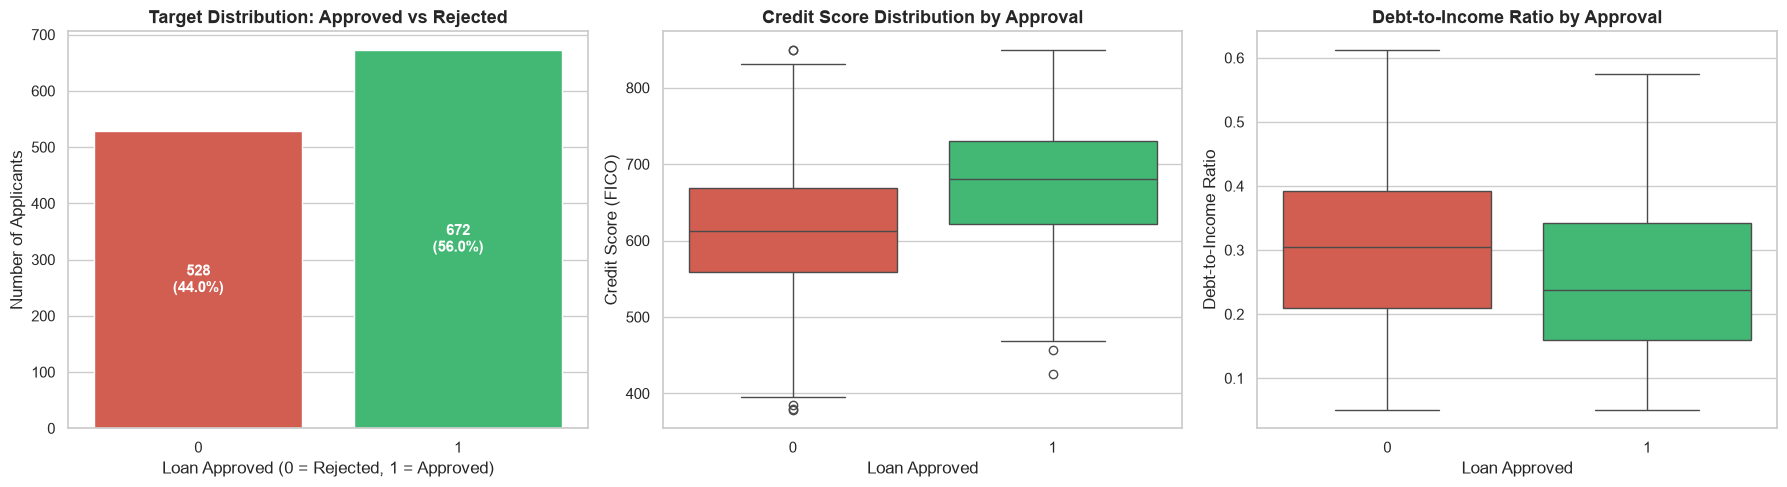

In [5]:
# Visualizing Exploratory Data Analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Target Class Balance
palette = ['#e74c3c', '#2ecc71']
sns.countplot(data=df, x='approved', ax=axes[0], hue='approved', palette=palette, legend=False)
axes[0].set_title("Target Distribution: Approved vs Rejected", fontweight='bold')
axes[0].set_xlabel("Loan Approved (0 = Rejected, 1 = Approved)")
axes[0].set_ylabel("Number of Applicants")
for p in axes[0].patches:
    h = p.get_height()
    axes[0].annotate(f"{int(h)}\n({h/len(df)*100:.1f}%)",
                     (p.get_x() + p.get_width() / 2., h / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Plot 2: Credit Score by Approval Status
sns.boxplot(data=df, x='approved', y='credit_score', ax=axes[1], hue='approved', palette=palette, legend=False)
axes[1].set_title("Credit Score Distribution by Approval", fontweight='bold')
axes[1].set_xlabel("Loan Approved")
axes[1].set_ylabel("Credit Score (FICO)")

# Plot 3: Debt-to-Income Ratio by Approval Status
sns.boxplot(data=df, x='approved', y='debt_to_income_ratio', ax=axes[2], hue='approved', palette=palette, legend=False)
axes[2].set_title("Debt-to-Income Ratio by Approval", fontweight='bold')
axes[2].set_xlabel("Loan Approved")
axes[2].set_ylabel("Debt-to-Income Ratio")

plt.tight_layout()
plt.show()

## 3. Data Preparation: Train-Test Split & Standardization

### 3.1 Separating Features ($X$) and Target ($y$)
Before training, we separate our predictive feature matrix $\mathbf{X}$ from the ground-truth target vector $\mathbf{y}$.

### 3.2 The Crucial Role of `random_state` and `stratify`
1. **`random_state=42`**: Pseudo-random number generator seed. In real ML workflows, setting `random_state` ensures that anyone executing this code obtains the exact same split and metrics.
2. **`stratify=y`**: Preserves the original class ratio in both training and testing subsets.
   - *Why it matters*: On moderately or heavily imbalanced datasets, unstratified random sampling can cause **sampling drift** — where the test set accidentally receives disproportionately few (or zero!) positive cases, invalidating metric calculations.

### 3.3 Feature Scaling (`StandardScaler`)
Logistic Regression computes linear combinations $\mathbf{w}^T\mathbf{x} + b$. Features with vastly different scales (e.g. `annual_income` in tens of thousands vs `debt_to_income_ratio` under 1.0) can distort regularization penalties ($L_2$) and hinder gradient descent convergence.
- **Data Leakage Prevention**: We fit the scaler **strictly on the training set** (`scaler.fit_transform(X_train)`), and use the learned parameters to transform the test set (`scaler.transform(X_test)`).

In [6]:
# Separate features and target
X = df.drop(columns=['approved'])
y = df['approved']

# 80/20 train/test split with stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]} samples (Approved ratio: {y_train.mean():.4f})")
print(f"Testing set size:  {X_test.shape[0]} samples (Approved ratio: {y_test.mean():.4f})")

Training set size: 960 samples (Approved ratio: 0.5604)
Testing set size:  240 samples (Approved ratio: 0.5583)


In [7]:
# Feature standardization (Z-score normalization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert to DataFrame for readable inspection
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
display(X_train_scaled_df.head(5).round(3))

,applicant_age,annual_income,credit_score,loan_amount,employment_years,debt_to_income_ratio
0,-1.613,-0.648,0.749,-0.701,-0.909,-0.849
1,-0.072,-0.514,-0.932,-0.935,-0.669,0.035
2,1.391,-0.698,-0.838,0.166,0.288,-0.218
3,-0.765,-0.170,0.550,0.212,0.134,-0.652
4,1.237,0.779,0.504,1.421,0.356,-1.135


## 4. Classification Model Training & Probabilities

### 4.1 Logistic Regression & The Sigmoid Function
Logistic Regression models the posterior probability of the positive class ($Y=1$) given inputs $\mathbf{x}$:
$$P(Y=1 | \mathbf{x}) = \sigma(z) = \frac{1}{1 + e^{-z}}$$
where $z = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_d x_d$ represents the **log-odds** (logit).

### 4.2 The Decision Threshold ($\tau = 0.5$)
A classifier outputs continuous probabilities $P(Y=1|\mathbf{x}) \in [0, 1]$. To make a binary decision $\hat{y} \in \{0, 1\}$, a **decision threshold (cutoff)** $\tau$ is applied:
$$\hat{y} = \begin{cases} 1 & \text{if } P(Y=1|\mathbf{x}) \ge \tau \\ 0 & \text{if } P(Y=1|\mathbf{x}) < \tau \end{cases}$$

By default, Scikit-learn's `model.predict()` uses $\tau = 0.5$. However, **0.5 is an arbitrary convention, not an immutable law**. In high-stakes business environments, we often adjust $\tau$ to trade off precision against recall.
- `model.predict(X_test)` $\rightarrow$ Returns discrete classes ($0$ or $1$) using default $\tau = 0.5$.
- `model.predict_proba(X_test)[:, 1]` $\rightarrow$ Returns the continuous probability scores $P(Y=1|\mathbf{x})$.


In [8]:
# Train Logistic Regression model
model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train_scaled, y_train)

# Generate discrete predictions (threshold = 0.5)
y_pred = model.predict(X_test_scaled)

# Generate continuous predicted probabilities
y_probs = model.predict_proba(X_test_scaled)[:, 1]

# Inspect sample predictions against actual labels
sample_eval = pd.DataFrame({
    'Actual Label (y_test)': y_test.values[:10],
    'Predicted Prob P(Y=1)': y_probs[:10].round(4),
    'Predicted Label (tau=0.5)': y_pred[:10]
})
display(sample_eval)

,Actual Label (y_test),Predicted Prob P(Y=1),Predicted Label (tau=0.5)
0,1,0.8632,1
1,1,0.4991,0
2,0,0.1110,0
3,0,0.3588,0
4,0,0.0928,0
5,1,0.9677,1
6,1,0.9509,1
7,1,0.5619,1
8,1,0.5688,1
9,0,0.7806,1


## 5. The Confusion Matrix: The Bedrock of Classification Evaluation

A **confusion matrix** is a cross-tabulation comparing actual ground-truth classes against model predictions across the test dataset.

### 5.1 The Four Quadrants
Every binary classification prediction falls into exactly one of four quadrants:

| | Predicted Negative ($\hat{y} = 0$) | Predicted Positive ($\hat{y} = 1$) |
| :--- | :--- | :--- |
| **Actual Negative ($y = 0$)** | **True Negative (TN)**<br>*(Correct Pass / True Rejection)* | **False Positive (FP)**<br>*(False Alarm / Type I Error)* |
| **Actual Positive ($y = 1$)** | **False Negative (FN)**<br>*(Missed Detection / Type II Error)* | **True Positive (TP)**<br>*(Correct Catch / True Approval)* |

### 5.2 Quadrant Definitions in the Loan Context:
1. **True Negative (TN)**: Applicant was unqualified ($y=0$), and the model correctly rejected them ($\hat{y}=0$).
2. **False Positive (FP)**: Applicant was unqualified ($y=0$), but the model mistakenly approved them ($\hat{y}=1$). **Cost**: High default risk and potential capital loss.
3. **False Negative (FN)**: Applicant was creditworthy ($y=1$), but the model mistakenly rejected them ($\hat{y}=0$). **Cost**: Lost interest revenue and dissatisfied applicant.
4. **True Positive (TP)**: Applicant was creditworthy ($y=1$), and the model correctly approved them ($\hat{y}=1$). **Benefit**: Safe interest income.

### 5.3 Memory Trick:
To decipher any quadrant name, break it into two questions:
- **First word (True / False)**: Was the model's call correct?
- **Second word (Positive / Negative)**: What call did the model make?

### 5.4 Scikit-Learn Orientation vs Statistical Tables:
Scikit-learn's `confusion_matrix(y_true, y_pred)` arranges rows as **Actual** and columns as **Predicted** in ascending order ($0$ then $1$):
$$\begin{bmatrix} \text{Actual } 0, \text{Pred } 0 \ (\mathbf{TN}) & \text{Actual } 0, \text{Pred } 1 \ (\mathbf{FP}) \\ \text{Actual } 1, \text{Pred } 0 \ (\mathbf{FN}) & \text{Actual } 1, \text{Pred } 1 \ (\mathbf{TP}) \end{bmatrix}$$
Using `.ravel()` on a 2x2 matrix extracts the counts in the exact sequence:
$$\text{tn, fp, fn, tp} = \text{confusion\_matrix}(y, \hat{y})\text{.ravel()}$$


In [9]:
# Compute confusion matrix and unpack quadrants
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("="*55)
print("             DECONSTRUCTED CONFUSION MATRIX")
print("="*55)
print(f"True Negatives  (TN - Correctly Rejected):  {tn}")
print(f"False Positives (FP - Unjustified Approval): {fp} (Type I Error)")
print(f"False Negatives (FN - Unjustified Reject):   {fn} (Type II Error)")
print(f"True Positives  (TP - Correctly Approved):  {tp}")
print("="*55)
print(f"Total Evaluated Test Samples: {len(y_test)}")

             DECONSTRUCTED CONFUSION MATRIX
True Negatives  (TN - Correctly Rejected):  74
False Positives (FP - Unjustified Approval): 32 (Type I Error)
False Negatives (FN - Unjustified Reject):   22 (Type II Error)
True Positives  (TP - Correctly Approved):  112
Total Evaluated Test Samples: 240


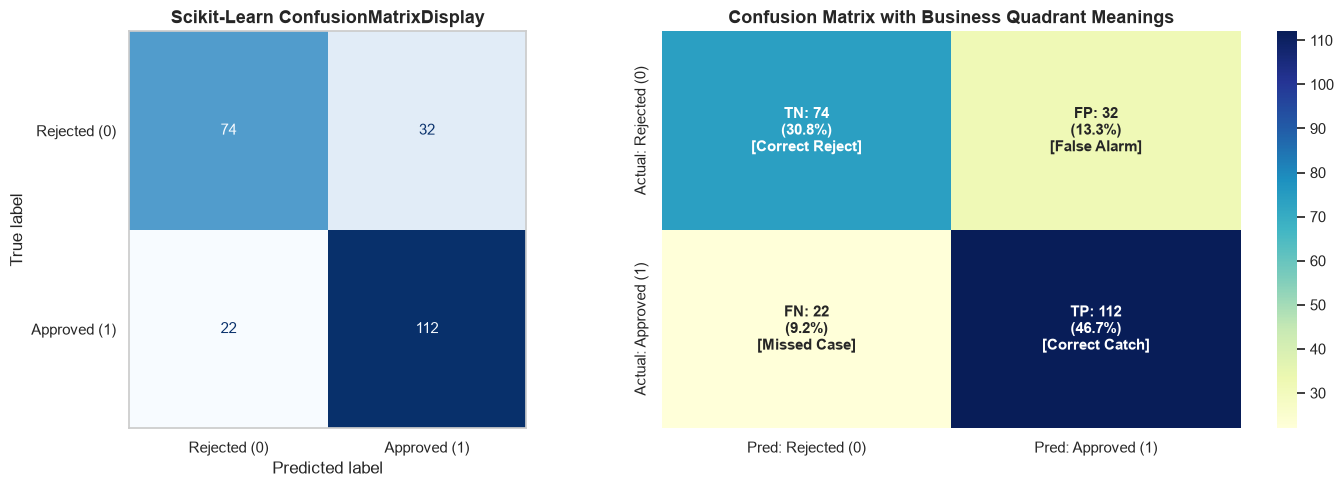

In [10]:
# Visualizing the Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Scikit-learn's built-in ConfusionMatrixDisplay
ConfusionMatrixDisplay(cm, display_labels=['Rejected (0)', 'Approved (1)']).plot(
    ax=axes[0], cmap='Blues', colorbar=False
)
axes[0].set_title("Scikit-Learn ConfusionMatrixDisplay", fontweight='bold')
axes[0].grid(False)

# 2. Rich Seaborn Heatmap with Quadrant Annotations and Percentages
annotations = np.array([
    [f"TN: {tn}\n({tn/len(y_test)*100:.1f}%)\n[Correct Reject]", f"FP: {fp}\n({fp/len(y_test)*100:.1f}%)\n[False Alarm]"],
    [f"FN: {fn}\n({fn/len(y_test)*100:.1f}%)\n[Missed Case]",    f"TP: {tp}\n({tp/len(y_test)*100:.1f}%)\n[Correct Catch]"]
])

sns.heatmap(cm, annot=annotations, fmt='', cmap='YlGnBu', cbar=True, ax=axes[1],
            xticklabels=['Pred: Rejected (0)', 'Pred: Approved (1)'],
            yticklabels=['Actual: Rejected (0)', 'Actual: Approved (1)'],
            annot_kws={'fontsize': 11, 'fontweight': 'bold'})
axes[1].set_title("Confusion Matrix with Business Quadrant Meanings", fontweight='bold')
axes[1].grid(False)

plt.tight_layout()
plt.show()

## 6. Deep Dive into Classification Metrics

---

### 6.1 Accuracy: The Overall Correctness
- **What it measures**: The overall percentage of predictions (both positive and negative) that the model got right.
- **Mathematical Formula**:
  $$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} = \frac{\text{Correct Predictions}}{\text{Total Predictions}}$$
- **Intuition**: Answers: *"Across the entire dataset, how often was the model right?"*
- **The Core Flaw**: True Negatives ($TN$) sit directly in the numerator. In problems where the negative class is massive, boring, and easy to classify (e.g. healthy patients, genuine card transactions), $TN$ swamps the metric, producing misleadingly high scores even when the model fails completely on the positive class.
- **When to Use**: Only when classes are **roughly balanced** and both types of errors (FP and FN) have **equal operational cost**.
- **When NOT to Use**: On imbalanced datasets, or when catching the minority positive class is critical.

In [11]:
# 6.1 Accuracy: Implementation and Verification
acc_sklearn = accuracy_score(y_test, y_pred)
acc_manual = (tp + tn) / (tp + tn + fp + fn)

print(f"Accuracy (scikit-learn): {acc_sklearn:.4f}")
print(f"Accuracy (manual):       {acc_manual:.4f}")
print(f"Exact match verified?    {np.isclose(acc_sklearn, acc_manual)}")
print(f"\nInterpretation: The model made correct decisions for {acc_sklearn*100:.2f}% of all test applicants.")

Accuracy (scikit-learn): 0.7750
Accuracy (manual):       0.7750
Exact match verified?    True

Interpretation: The model made correct decisions for 77.50% of all test applicants.


### 6.2 Precision: Positive Predictive Value
- **What it measures**: The proportion of positive predictions that were truly positive.
- **Mathematical Formula**:
  $$\text{Precision} = \frac{TP}{TP + FP}$$
- **Intuition**: Answers: *"Of everyone the model approved, how many actually deserved it?"* Or in spam: *"Of all emails marked spam, how many were actually spam?"*
- **Business Focus**: **Minimizing False Positives (False Alarms)**. Precision ignores $TN$ entirely and focuses only on the positive predictions column.
- **Primary Example**: **Spam Filtering**. If a legitimate email (work offer, client invoice) is marked as spam (False Positive), the user may never see it — causing immediate harm. A spam filter must be highly precise.
- **When to Prioritize**: When **acting on a false alarm is expensive, damaging, or irreversible** (e.g., automated account banning, sending aggressive debt collection notices, spam filtering).
- **When NOT to Rely on Alone**: A model that only makes 1 prediction all day on its single most confident sample can achieve 100% precision while missing 99% of all other actual cases!

In [12]:
# 6.2 Precision: Implementation and Verification
prec_sklearn = precision_score(y_test, y_pred)
prec_manual = tp / (tp + fp)

print(f"Precision (scikit-learn): {prec_sklearn:.4f}")
print(f"Precision (manual):       {prec_manual:.4f}")
print(f"Exact match verified?     {np.isclose(prec_sklearn, prec_manual)}")
print(f"\nInterpretation: When the model approves an applicant, it is correct {prec_sklearn*100:.2f}% of the time.")
print(f"False Alarm Rate in Approvals: {(1 - prec_sklearn)*100:.2f}% of approved applicants are actually unqualified.")

Precision (scikit-learn): 0.7778
Precision (manual):       0.7778
Exact match verified?     True

Interpretation: When the model approves an applicant, it is correct 77.78% of the time.
False Alarm Rate in Approvals: 22.22% of approved applicants are actually unqualified.


### 6.3 Recall / Sensitivity: True Positive Rate (Hit Rate)
- **What it measures**: The proportion of actual positive cases that the model successfully detected.
- **Mathematical Formula**:
  $$\text{Recall} = \frac{TP}{TP + FN}$$
- **Intuition**: Answers: *"Of all applicants who truly deserved approval, how many did the model find?"* Or in medicine: *"Of all patients who actually have the disease, how many did we diagnose?"*
- **Business Focus**: **Minimizing False Negatives (Missed Detections)**. Recall looks across the actual positive row.
- **Primary Example**: **Cancer Screening & Fraud Detection**. Missing a malignant tumor (False Negative) can result in patient death; failing to detect a $10,000 fraudulent wire transfer causes unreimbursed financial loss.
- **When to Prioritize**: When **missing a positive case is catastrophic, hazardous, or costly** (disease diagnostics, credit card fraud, factory equipment failure detection, security intrusions).
- **When NOT to Rely on Alone**: A model that trivially predicts `1` for every sample achieves 100% recall, but has disastrous precision and provides zero selective discrimination.

In [13]:
# 6.3 Recall: Implementation and Verification
rec_sklearn = recall_score(y_test, y_pred)
rec_manual = tp / (tp + fn)

print(f"Recall (scikit-learn): {rec_sklearn:.4f}")
print(f"Recall (manual):       {rec_manual:.4f}")
print(f"Exact match verified?  {np.isclose(rec_sklearn, rec_manual)}")
print(f"\nInterpretation: The model successfully caught {rec_sklearn*100:.2f}% of all genuinely qualified applicants.")
print(f"Miss Rate: The model mistakenly turned away {(1 - rec_sklearn)*100:.2f}% of creditworthy borrowers.")

Recall (scikit-learn): 0.8358
Recall (manual):       0.8358
Exact match verified?  True

Interpretation: The model successfully caught 83.58% of all genuinely qualified applicants.
Miss Rate: The model mistakenly turned away 16.42% of creditworthy borrowers.


### 6.4 Specificity (True Negative Rate) & False Positive Rate
- **What Specificity measures**: The proportion of actual negative cases that the model correctly identified as negative.
- **Mathematical Formula**:
  $$\text{Specificity} = \frac{TN}{TN + FP}$$
- **False Positive Rate (FPR)**: The proportion of actual negatives mistakenly called positive:
  $$\text{FPR} = \frac{FP}{FP + TN} = 1 - \text{Specificity}$$
- **Intuition**: Specificity is to the negative class what Recall is to the positive class.
- **Role in Classification**: Forms the horizontal axis of the **ROC Curve** ($x = \text{FPR} = 1 - \text{Specificity}$, $y = \text{TPR} = \text{Recall}$).

In [14]:
# 6.4 Specificity and False Positive Rate
specificity = tn / (tn + fp)
fpr_val = fp / (fp + tn)

print(f"Specificity (True Negative Rate): {specificity:.4f}")
print(f"False Positive Rate (FPR):       {fpr_val:.4f}")
print(f"Identity Check (Specificity + FPR = 1.0): {specificity + fpr_val:.4f}")
print(f"\nInterpretation: The model correctly identified {specificity*100:.2f}% of unqualified applicants.")

Specificity (True Negative Rate): 0.6981
False Positive Rate (FPR):       0.3019
Identity Check (Specificity + FPR = 1.0): 1.0000

Interpretation: The model correctly identified 69.81% of unqualified applicants.


### 6.5 F1-Score: The Harmonic Mean of Precision and Recall
- **What it measures**: A single balanced metric combining Precision and Recall.
- **Mathematical Formula**:
  $$\text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}} = \frac{2 \cdot TP}{2 \cdot TP + FP + FN}$$

#### Why the Harmonic Mean Instead of the Arithmetic Mean?
The arithmetic mean $\frac{P + R}{2}$ treats both scores independently. If a degenerate model has $\text{Precision} = 1.0$ and $\text{Recall} = 0.04$, its arithmetic average is:
$$\frac{1.0 + 0.04}{2} = 0.52 \quad (\text{misleadingly optimistic!})$$
The **harmonic mean**, however, computes the reciprocal of the arithmetic mean of reciprocals:
$$\text{F1} = \frac{2}{\frac{1}{P} + \frac{1}{R}} = \frac{2 \times 1.0 \times 0.04}{1.0 + 0.04} \approx 0.077$$
**Key Property**: The harmonic mean **heavily penalizes extreme discrepancies** between Precision and Recall. The F1-score is close to the lower value whenever there is a wide gap, and only achieves a high value when **both** Precision and Recall are strong.

In [15]:
# 6.5 F1-Score: Implementation and Mean Comparison Experiment
f1_sklearn = f1_score(y_test, y_pred)
f1_manual = 2 * (prec_manual * rec_manual) / (prec_manual + rec_manual)

print(f"F1-Score (scikit-learn): {f1_sklearn:.4f}")
print(f"F1-Score (manual):       {f1_manual:.4f}")
print(f"Exact match verified?    {np.isclose(f1_sklearn, f1_manual)}")

# Numerical demonstration: Arithmetic Mean vs Harmonic Mean (F1)
demo_scenarios = [
    ("Balanced High Performance", 0.85, 0.85),
    ("Moderate Performance", 0.75, 0.60),
    ("High Precision, Low Recall", 0.95, 0.10),
    ("Low Precision, High Recall", 0.15, 0.95),
]

mean_rows = []
for name, p, r in demo_scenarios:
    am = (p + r) / 2
    hm = 2 * p * r / (p + r) if (p + r) > 0 else 0
    mean_rows.append({
        'Scenario': name,
        'Precision': p,
        'Recall': r,
        'Arithmetic Mean': round(am, 4),
        'Harmonic Mean (F1)': round(hm, 4),
        'Disparity Penalty': round(am - hm, 4)
    })

display(pd.DataFrame(mean_rows))

F1-Score (scikit-learn): 0.8058
F1-Score (manual):       0.8058
Exact match verified?    True


,Scenario,Precision,Recall,Arithmetic Mean,Harmonic Mean (F1),Disparity Penalty
0,Balanced High Performance,0.85,0.85,0.850,0.8500,0.0000
1,Moderate Performance,0.75,0.60,0.675,0.6667,0.0083
2,"High Precision, Low Recall",0.95,0.10,0.525,0.1810,0.3440
3,"Low Precision, High Recall",0.15,0.95,0.550,0.2591,0.2909


### 6.6 Scikit-Learn Classification Report & Multi-Class Averaging
Scikit-learn's `classification_report` produces a complete summary across all classes:
- **Support**: The actual number of ground-truth occurrences of each class in the test set.
- **Macro Average**: Computes metrics independently for each class and calculates their unweighted arithmetic mean:
  $$\text{Macro } F_1 = \frac{1}{K} \sum_{k=1}^K F_{1, k}$$
  *Best used when*: You care equally about all classes regardless of class frequency. Highly sensitive to minority class performance.
- **Weighted Average**: Averages metrics weighted by the support of each class:
  $$\text{Weighted } F_1 = \sum_{k=1}^K \frac{N_k}{N} F_{1, k}$$
  *Best used when*: You want a score reflective of overall dataset prevalence (though it can mask poor minority performance).
- **Micro Average**: Aggregates total $TP, FP, FN$ globally across all classes. In single-label multiclass, Micro $F_1 = \text{Accuracy}$.

In [16]:
# 6.6 Classification Report
print("====================== CLASSIFICATION REPORT ======================")
print(classification_report(y_test, y_pred, digits=4, target_names=['Rejected (0)', 'Approved (1)']))

====================== CLASSIFICATION REPORT ======================
              precision    recall  f1-score   support

Rejected (0)     0.7708    0.6981    0.7327       106
Approved (1)     0.7778    0.8358    0.8058       134

    accuracy                         0.7750       240
   macro avg     0.7743    0.7670    0.7692       240
weighted avg     0.7747    0.7750    0.7735       240



### 6.7 Log Loss (Binary Cross-Entropy)
- **What it measures**: The accuracy of predicted probabilities rather than just discrete class assignments.
- **Mathematical Formula**:
  $$\text{Log Loss} = - \frac{1}{N} \sum_{i=1}^N \left[ y_i \ln(p_i) + (1 - y_i) \ln(1 - p_i) \right]$$
  where $p_i = P(y_i = 1 | \mathbf{x}_i)$.
- **Intuition**: Unlike accuracy, precision, and recall (which look only at 0 or 1 decisions), Log Loss **heavily penalizes overconfident wrong predictions**.
  - Predicting $p = 0.51$ for an actual class 0 incurs modest loss ($\approx 0.71$).
  - Predicting $p = 0.999$ for an actual class 0 incurs catastrophic loss ($\approx 6.91$).
- **When to Use**: When probability calibration matters (e.g. risk pricing, weather forecasting, sports betting, confidence-weighted routing).

In [17]:
# 6.7 Log Loss Implementation and Sensitivity Demonstration
loss_actual = log_loss(y_test, y_probs)
print(f"Model Log Loss: {loss_actual:.4f}")

# Compare against synthetic model confidence profiles:
near_perfect_probs = np.where(y_test == 1, 0.99, 0.01)
random_guess_probs = np.full_like(y_test, 0.5, dtype=float)
confidently_wrong_probs = np.where(y_test == 1, 0.01, 0.99) # Disastrous

print(f"Log Loss (Near-Perfect Calibrated Model): {log_loss(y_test, near_perfect_probs):.4f}")
print(f"Log Loss (Random Guess 50/50 Probabilities): {log_loss(y_test, random_guess_probs):.4f}")
print(f"Log Loss (Confidently Wrong Model):           {log_loss(y_test, confidently_wrong_probs):.4f}")

Model Log Loss: 0.4630
Log Loss (Near-Perfect Calibrated Model): 0.0101
Log Loss (Random Guess 50/50 Probabilities): 0.6931
Log Loss (Confidently Wrong Model):           4.6052


## 7. Probability Cutoffs & The Precision-Recall Trade-off

### 7.1 The Decision Threshold as an Operational Business Dial
A classification model outputs continuous probability estimates $P(Y=1|\mathbf{x})$. Converting probabilities into decisions requires picking a threshold $\tau$:
- **Lowering the Threshold ($\tau < 0.5$, e.g. $\tau = 0.3$)**:
  - The model becomes **more aggressive** in predicting Positive.
  - **Effect**: Catches nearly all actual positives ($\mathbf{Recall \uparrow}$), but lets in more false alarms ($\mathbf{Precision \downarrow}$).
  - *Business fit*: Medical screening, security intrusion detection, fraud prevention.
- **Raising the Threshold ($\tau > 0.5$, e.g. $\tau = 0.7$)**:
  - The model becomes **more conservative**, requiring stronger evidence to call Positive.
  - **Effect**: Positive calls are highly trustworthy ($\mathbf{Precision \uparrow}$), but more real positive cases slip through undetected ($\mathbf{Recall \downarrow}$).
  - *Business fit*: Email spam filtering, automated account terminations, high-value loan disbursements without human review.

There is no threshold that simultaneously maximizes both Precision and Recall (except in the trivial case of a perfect classifier). Moving $\tau$ shifts you along the trade-off curve.

In [18]:
# Sweeping Decision Thresholds from 0.05 to 0.95
threshold_range = np.arange(0.05, 1.00, 0.05)
sweep_records = []

for t in threshold_range:
    preds_t = (y_probs >= t).astype(int)
    cm_t = confusion_matrix(y_test, preds_t)
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel()
    
    p_t = precision_score(y_test, preds_t, zero_division=0)
    r_t = recall_score(y_test, preds_t, zero_division=0)
    f1_t = f1_score(y_test, preds_t, zero_division=0)
    acc_t = accuracy_score(y_test, preds_t)
    
    sweep_records.append({
        'Threshold (tau)': round(t, 2),
        'TP': tp_t, 'FP': fp_t, 'FN': fn_t, 'TN': tn_t,
        'Accuracy': round(acc_t, 4),
        'Precision': round(p_t, 4),
        'Recall': round(r_t, 4),
        'F1-Score': round(f1_t, 4)
    })

sweep_table = pd.DataFrame(sweep_records)

# Display representative thresholds across low, default, and high regimes
display_subset = sweep_table[sweep_table['Threshold (tau)'].isin([0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80])]
display(display_subset)

,Threshold (tau),TP,FP,FN,TN,Accuracy,Precision,Recall,F1-Score
3,0.2,133,74,1,32,0.6875,0.6425,0.9925,0.7801
5,0.3,128,61,6,45,0.7208,0.6772,0.9552,0.7926
7,0.4,121,45,13,61,0.7583,0.7289,0.9030,0.8067
9,0.5,112,32,22,74,0.7750,0.7778,0.8358,0.8058
11,0.6,99,20,35,86,0.7708,0.8319,0.7388,0.7826
13,0.7,82,12,52,94,0.7333,0.8723,0.6119,0.7193
15,0.8,58,4,76,102,0.6667,0.9355,0.4328,0.5918


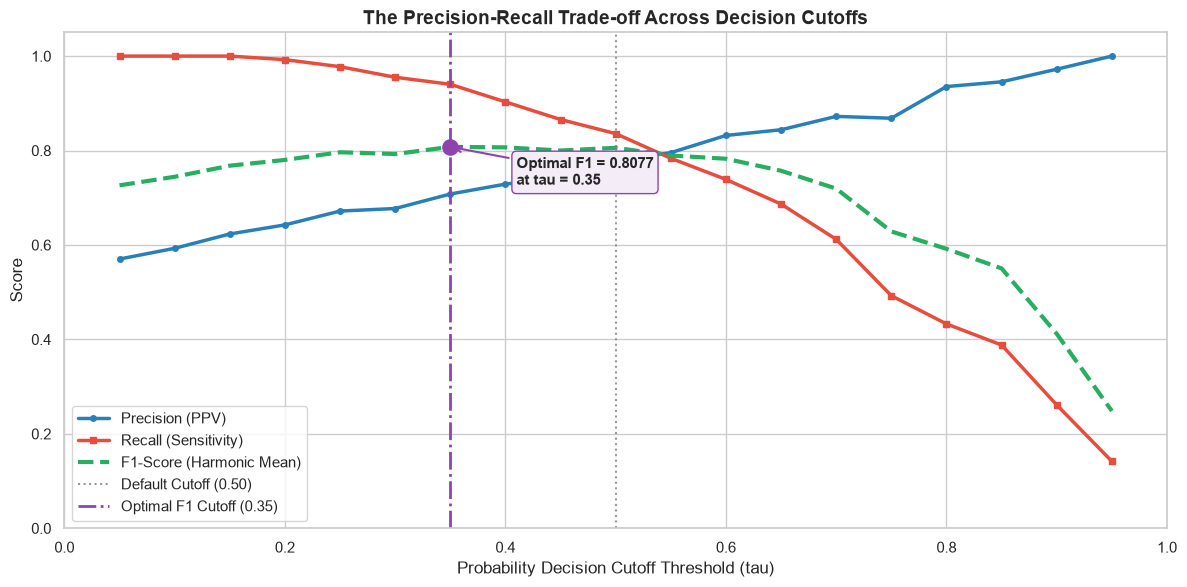

In [19]:
# Visualizing the Precision-Recall-F1 Trade-off Curve
plt.figure(figsize=(12, 6))

plt.plot(sweep_table['Threshold (tau)'], sweep_table['Precision'], label='Precision (PPV)', color='#2980b9', lw=2.5, marker='o', markersize=4)
plt.plot(sweep_table['Threshold (tau)'], sweep_table['Recall'], label='Recall (Sensitivity)', color='#e74c3c', lw=2.5, marker='s', markersize=4)
plt.plot(sweep_table['Threshold (tau)'], sweep_table['F1-Score'], label='F1-Score (Harmonic Mean)', color='#27ae60', lw=3, linestyle='--')

# Find peak F1 threshold
best_idx = sweep_table['F1-Score'].idxmax()
opt_tau = sweep_table.loc[best_idx, 'Threshold (tau)']
opt_f1 = sweep_table.loc[best_idx, 'F1-Score']

plt.axvline(x=0.50, color='gray', linestyle=':', label='Default Cutoff (0.50)', alpha=0.8)
plt.axvline(x=opt_tau, color='#8e44ad', linestyle='-.', lw=2, label=f'Optimal F1 Cutoff ({opt_tau:.2f})')
plt.scatter([opt_tau], [opt_f1], color='#8e44ad', s=120, zorder=5)

plt.annotate(f"Optimal F1 = {opt_f1:.4f}\nat tau = {opt_tau:.2f}",
             xy=(opt_tau, opt_f1), xytext=(opt_tau + 0.06, opt_f1 - 0.08),
             arrowprops=dict(arrowstyle="->", color='#8e44ad', lw=1.5),
             fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="#f4ecf7", ec="#8e44ad"))

plt.title("The Precision-Recall Trade-off Across Decision Cutoffs", fontsize=14, fontweight='bold')
plt.xlabel("Probability Decision Cutoff Threshold (tau)", fontsize=12)
plt.ylabel("Score", fontsize=12)
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.show()

## 8. Evaluating Classifiers Across All Thresholds: ROC & PR Curves

Instead of evaluating performance at a single fixed threshold (like 0.5), we can evaluate the classifier across **all possible continuous thresholds simultaneously**.

---

### 8.1 Receiver Operating Characteristic (ROC) Curve & Area Under the Curve (ROC-AUC)
- **What it plots**:
  - Vertical Axis ($y$): **True Positive Rate (TPR / Recall / Sensitivity)** $= \frac{TP}{TP + FN}$
  - Horizontal Axis ($x$): **False Positive Rate (FPR)** $= \frac{FP}{FP + TN} = 1 - \text{Specificity}$
- **What ROC-AUC represents**:
  - The probability that a randomly selected positive instance will receive a **higher predicted probability score** than a randomly selected negative instance.
  - A metric of **ranking capability**, completely independent of any chosen decision cutoff!

#### Standard Interpretation of ROC-AUC:
| ROC-AUC Range | Interpretation |
| :--- | :--- |
| **$1.0$** | **Perfect Discrimination**: Every positive scored higher than every negative. |
| **$0.90 - 1.00$** | **Outstanding**: Exceptional discriminative separation. |
| **$0.80 - 0.90$** | **Excellent**: Strong real-world predictive utility (our model lands here!). |
| **$0.70 - 0.80$** | **Acceptable**: Meaningfully better than chance, with room for improvement. |
| **$0.50$** | **No Skill**: Equivalent to flipping a fair coin (diagonal reference line). |
| **$< 0.50$** | **Inverted**: The model's predictions are worse than random; reversing predictions improves it. |


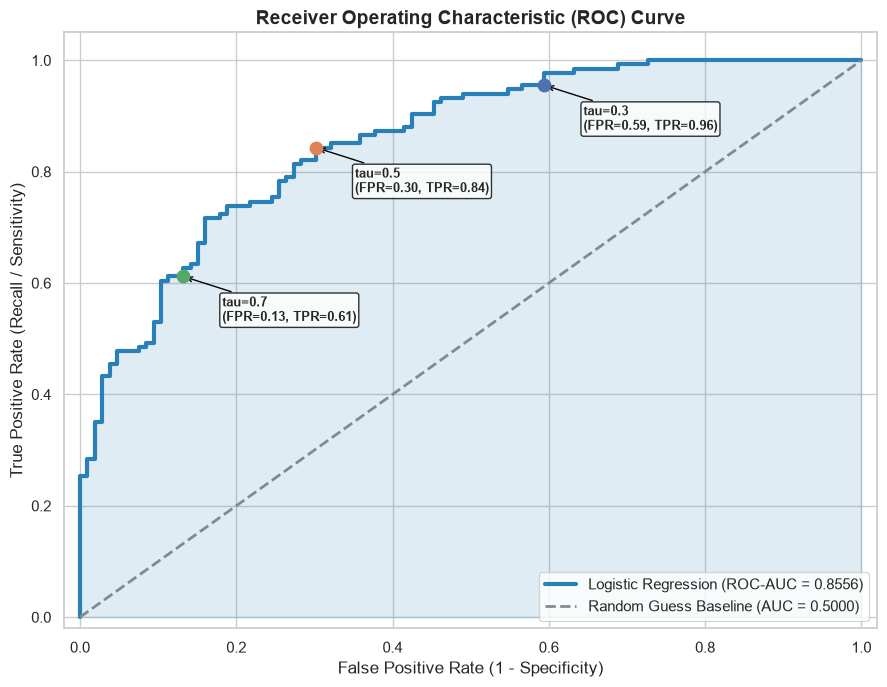

Calculated ROC-AUC Score: 0.8556


In [20]:
# Compute ROC Curve and ROC-AUC
fpr_curve, tpr_curve, roc_thresholds = roc_curve(y_test, y_probs)
auc_score = roc_auc_score(y_test, y_probs)

plt.figure(figsize=(9, 7))
plt.plot(fpr_curve, tpr_curve, color='#2980b9', lw=3, label=f'Logistic Regression (ROC-AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='#7f8c8d', lw=2, linestyle='--', label='Random Guess Baseline (AUC = 0.5000)')
plt.fill_between(fpr_curve, tpr_curve, alpha=0.15, color='#2980b9')

# Annotate specific cutoff points along the curve
for target_t in [0.30, 0.50, 0.70]:
    closest_idx = np.argmin(np.abs(roc_thresholds - target_t))
    plt.scatter(fpr_curve[closest_idx], tpr_curve[closest_idx], s=80, zorder=5)
    plt.annotate(f"tau={target_t}\n(FPR={fpr_curve[closest_idx]:.2f}, TPR={tpr_curve[closest_idx]:.2f})",
                 xy=(fpr_curve[closest_idx], tpr_curve[closest_idx]),
                 xytext=(fpr_curve[closest_idx] + 0.05, tpr_curve[closest_idx] - 0.08),
                 arrowprops=dict(arrowstyle="->", color='black'),
                 fontsize=9, fontweight='bold', bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="black", alpha=0.8))

plt.title("Receiver Operating Characteristic (ROC) Curve", fontsize=14, fontweight='bold')
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
plt.ylabel("True Positive Rate (Recall / Sensitivity)", fontsize=12)
plt.xlim(-0.02, 1.02)
plt.ylim(-0.02, 1.05)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

print(f"Calculated ROC-AUC Score: {auc_score:.4f}")

### 8.2 Precision-Recall (PR) Curve & Average Precision (PR-AUC)
- **What it plots**:
  - Vertical Axis ($y$): **Precision** $= \frac{TP}{TP + FP}$
  - Horizontal Axis ($x$): **Recall** $= \frac{TP}{TP + FN}$
- **Baseline**: Unlike the ROC baseline (which is always 0.5), the **no-skill PR baseline equals the positive class prevalence**:
  $$\text{Baseline} = \frac{P}{P + N} = \frac{\text{Actual Positives}}{\text{Total Samples}}$$
- **Why PR-AUC is Critical on Imbalanced Data**:
  - The ROC curve includes $FP / (FP + TN)$ on the horizontal axis. When $TN$ is enormous (e.g. 99,000 negatives and 1,000 positives), a model can make thousands of false alarms ($FP = 2,000$), yet $FPR = 2,000 / 101,000 \approx 0.019$ remains tiny, making the ROC curve look deceptively fantastic!
  - In contrast, Precision is $\frac{TP}{TP + FP}$. The $FP$ term directly degrades Precision, immediately exposing the flood of false alarms.
  - **Rule of Thumb**: When the minority positive class is rare ($< 10\%$), **always prioritize the Precision-Recall curve over the ROC curve**.

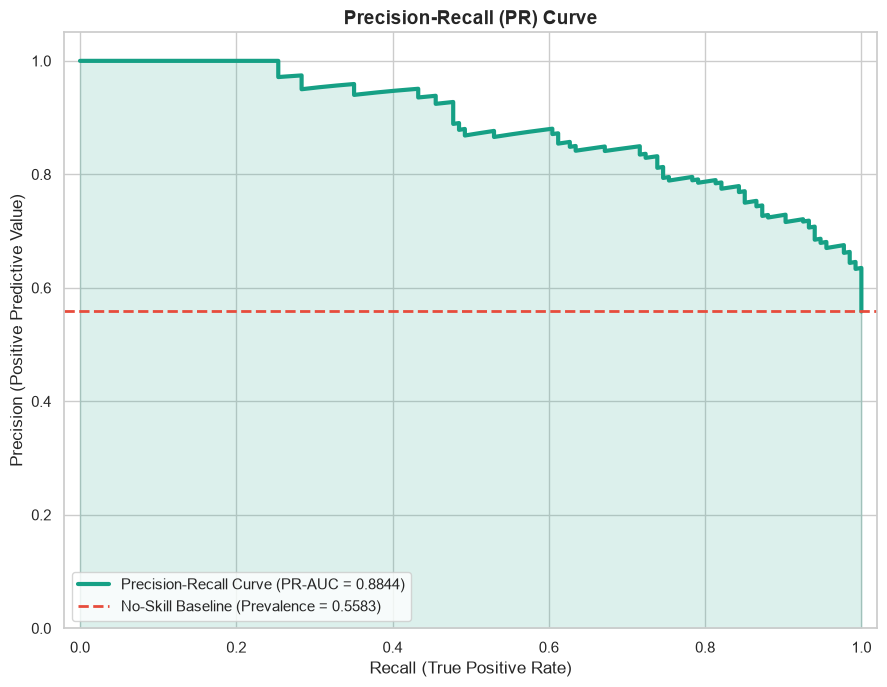

Precision-Recall AUC (Average Precision): 0.8844
Positive Class Prevalence:                0.5583


In [21]:
# Compute Precision-Recall Curve and PR-AUC (Average Precision)
prec_curve, rec_curve, pr_thresholds = precision_recall_curve(y_test, y_probs)
pr_auc_score = average_precision_score(y_test, y_probs)
prevalence = y_test.mean()

plt.figure(figsize=(9, 7))
plt.plot(rec_curve, prec_curve, color='#16a085', lw=3, label=f'Precision-Recall Curve (PR-AUC = {pr_auc_score:.4f})')
plt.axhline(y=prevalence, color='#e74c3c', linestyle='--', lw=2,
            label=f'No-Skill Baseline (Prevalence = {prevalence:.4f})')
plt.fill_between(rec_curve, prec_curve, alpha=0.15, color='#16a085')

plt.title("Precision-Recall (PR) Curve", fontsize=14, fontweight='bold')
plt.xlabel("Recall (True Positive Rate)", fontsize=12)
plt.ylabel("Precision (Positive Predictive Value)", fontsize=12)
plt.xlim(-0.02, 1.02)
plt.ylim(0, 1.05)
plt.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.show()

print(f"Precision-Recall AUC (Average Precision): {pr_auc_score:.4f}")
print(f"Positive Class Prevalence:                {prevalence:.4f}")

## 9. Imbalanced Classification & The Accuracy Paradox

To experience firsthand why accuracy breaks down, let us simulate a severe real-world imbalance scenario:
- **Class 0 (Genuine Transactions / Healthy Cases)**: $95\%$
- **Class 1 (Fraud / Critical Disease)**: $5\%$

We compare two models:
1. **The "Dummy" Classifier**: A trivial heuristic that always predicts the majority class (`0`), never learning from the data.
2. **Logistic Regression Classifier**: A trained machine learning model.

In [22]:
# Simulate severe class imbalance (95% majority, 5% minority)
np.random.seed(42)
X_imb, y_imb = make_classification(
    n_samples=2000,
    n_features=6,
    weights=[0.95, 0.05], # 95% negative, 5% positive
    random_state=42
)

X_tr_imb, X_te_imb, y_tr_imb, y_te_imb = train_test_split(
    X_imb, y_imb, test_size=0.25, random_state=42, stratify=y_imb
)

# 1. Dummy Classifier (always predicts 0)
dummy_clf = DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X_tr_imb, y_tr_imb)
dummy_preds = dummy_clf.predict(X_te_imb)

# 2. Trained Logistic Regression
lr_imb = LogisticRegression(random_state=42)
lr_imb.fit(X_tr_imb, y_tr_imb)
lr_preds = lr_imb.predict(X_te_imb)
lr_probs = lr_imb.predict_proba(X_te_imb)[:, 1]

# Comparison Table
imb_summary = pd.DataFrame({
    'Evaluation Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC'],
    'Dummy Classifier (Always Majority)': [
        accuracy_score(y_te_imb, dummy_preds),
        precision_score(y_te_imb, dummy_preds, zero_division=0),
        recall_score(y_te_imb, dummy_preds, zero_division=0),
        f1_score(y_te_imb, dummy_preds, zero_division=0),
        roc_auc_score(y_te_imb, np.zeros_like(y_te_imb)),
        average_precision_score(y_te_imb, np.zeros_like(y_te_imb))
    ],
    'Trained Logistic Regression': [
        accuracy_score(y_te_imb, lr_preds),
        precision_score(y_te_imb, lr_preds, zero_division=0),
        recall_score(y_te_imb, lr_preds, zero_division=0),
        f1_score(y_te_imb, lr_preds, zero_division=0),
        roc_auc_score(y_te_imb, lr_probs),
        average_precision_score(y_te_imb, lr_probs)
    ]
})

print(f"Test Set Class Counts: {pd.Series(y_te_imb).value_counts().to_dict()}")
display(imb_summary.round(4))

Test Set Class Counts: {0: 472, 1: 28}


,Evaluation Metric,Dummy Classifier (Always Majority),Trained Logistic Regression
0,Accuracy,0.944,0.9560
1,Precision,0.000,0.7143
2,Recall,0.000,0.3571
3,F1-Score,0.000,0.4762
4,ROC-AUC,0.500,0.8603
5,PR-AUC,0.056,0.5850


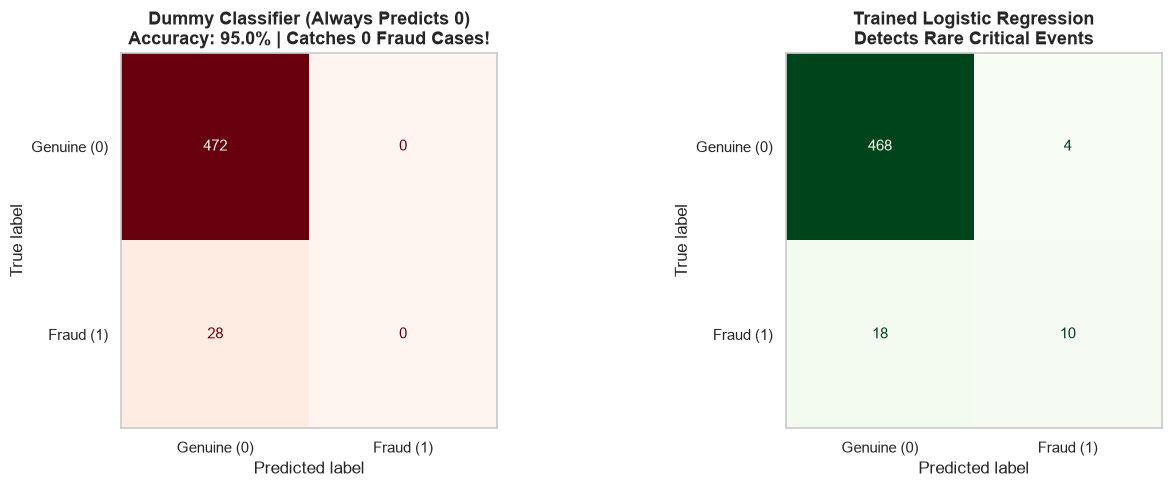

In [23]:
# Visualizing Confusion Matrices Under Severe Imbalance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_te_imb, dummy_preds, display_labels=['Genuine (0)', 'Fraud (1)'], ax=axes[0], cmap='Reds', colorbar=False
)
axes[0].set_title("Dummy Classifier (Always Predicts 0)\nAccuracy: 95.0% | Catches 0 Fraud Cases!", fontweight='bold')
axes[0].grid(False)

ConfusionMatrixDisplay.from_predictions(
    y_te_imb, lr_preds, display_labels=['Genuine (0)', 'Fraud (1)'], ax=axes[1], cmap='Greens', colorbar=False
)
axes[1].set_title("Trained Logistic Regression\nDetects Rare Critical Events", fontweight='bold')
axes[1].grid(False)

plt.tight_layout()
plt.show()

## 10. Multiclass Classification Metrics (Extension)

In problems with $K > 2$ classes (e.g. Iris species, document categorization), metrics extend through **One-vs-Rest (OvR)** aggregation:
- **Macro Average**: Computes the metric for Class 1, Class 2, ..., Class $K$ independently, then takes their unweighted arithmetic mean.
  $$\text{Macro } F_1 = \frac{F_{1,\text{class 1}} + F_{1,\text{class 2}} + \dots + F_{1,\text{class } K}}{K}$$
  *Key Trait*: Treats every class equally. Ideal when minority classes are equally important.
- **Weighted Average**: Weights each class metric by its support ($N_k / N$).
  *Key Trait*: Reflects real-world class frequency, but masks poor performance on tiny classes.
- **Micro Average**: Aggregates all $TP, FP, FN$ across the global pool first, then computes the metric. In single-label multiclass, Micro $F_1 \equiv \text{Accuracy}$.

In [24]:
# Multiclass Demonstration using Iris Dataset
iris = load_iris()
X_iris, y_iris = iris.data, iris.target

X_tr_iris, X_te_iris, y_tr_iris, y_te_iris = train_test_split(
    X_iris, y_iris, test_size=0.30, random_state=42, stratify=y_iris
)

multi_clf = LogisticRegression(max_iter=500, random_state=42)
multi_clf.fit(X_tr_iris, y_tr_iris)
y_multi_pred = multi_clf.predict(X_te_iris)

print("================ MULTICLASS CLASSIFICATION REPORT ================")
print(classification_report(y_te_iris, y_multi_pred, target_names=iris.target_names, digits=4))

# Explicit verification of averaging mechanics
macro_val = f1_score(y_te_iris, y_multi_pred, average='macro')
weighted_val = f1_score(y_te_iris, y_multi_pred, average='weighted')
micro_val = f1_score(y_te_iris, y_multi_pred, average='micro')

print(f"Macro F1    (Unweighted mean):         {macro_val:.4f}")
print(f"Weighted F1 (Support-weighted mean):   {weighted_val:.4f}")
print(f"Micro F1    (Global instance average): {micro_val:.4f}")

================ MULTICLASS CLASSIFICATION REPORT ================
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        15
  versicolor     0.8750    0.9333    0.9032        15
   virginica     0.9286    0.8667    0.8966        15

    accuracy                         0.9333        45
   macro avg     0.9345    0.9333    0.9333        45
weighted avg     0.9345    0.9333    0.9333        45

Macro F1    (Unweighted mean):         0.9333
Weighted F1 (Support-weighted mean):   0.9333
Micro F1    (Global instance average): 0.9333


## 11. Metric Comparison Master Table & Practical Decision Framework

---

### 11.1 Master Comparison Table

| Metric | What It Measures | Mathematical Formula | Best Used When | Limitations & Common Pitfalls |
| :--- | :--- | :--- | :--- | :--- |
| **Accuracy** | Fraction of total predictions that are correct. | $\frac{TP + TN}{TP + TN + FP + FN}$ | Classes are roughly balanced AND error costs are symmetric. | Dangerously misleading under class imbalance; dominated by high True Negatives. |
| **Precision** | Fraction of positive predictions that are truly positive. | $\frac{TP}{TP + FP}$ | False alarms (FP) are expensive, harmful, or irreversible (e.g. spam filter). | Ignores missed cases (FN); can be gamed by making very few confident positive calls. |
| **Recall (Sensitivity)** | Fraction of actual positive cases successfully caught. | $\frac{TP}{TP + FN}$ | Missed cases (FN) are hazardous or catastrophic (e.g. cancer, fraud). | Ignores false alarms (FP); trivially maxed out by predicting 1 for everything. |
| **Specificity** | Fraction of actual negative cases correctly identified. | $\frac{TN}{TN + FP}$ | Need to verify coverage of the healthy/baseline class. | Irrelevant if the negative class carries no operational value. |
| **F1-Score** | Harmonic mean balancing Precision and Recall. | $2 \cdot \frac{P \cdot R}{P + R} = \frac{2TP}{2TP + FP + FN}$ | Need a single balanced summary and both FP and FN matter. | Treats Precision and Recall with equal weight; hides whether error is FP or FN. |
| **ROC-AUC** | Overall model ranking capability across all cutoffs. | Area under $\text{TPR}$ vs $\text{FPR}$ curve | Evaluating and comparing candidate models before setting an operating threshold. | Can look deceptively high on severely imbalanced datasets due to large $TN$. |
| **PR-AUC** | Area under the Precision-Recall curve. | Area under Precision vs Recall curve | Severely imbalanced problems where the minority class is the sole focus. | Baseline changes with positive prevalence; harder to compare across different datasets. |
| **Log Loss** | Probabilistic confidence penalty. | $-\frac{1}{N}\sum [y\ln(p) + (1-y)\ln(1-p)]$ | Probability calibration and prediction confidence matter directly. | Less intuitive to interpret in non-technical business terms than percentage metrics. |


### 11.2 Practical Decision Framework: Which Metric Should You Optimize?

#### 1. When should I optimize for Precision?
- **Rule**: Optimize for Precision when **False Positives are significantly more costly than False Negatives**.
- **Real-World Scenarios**:
  - *Email Spam Filters*: Sending an important contract or job offer to the spam folder is intolerable.
  - *Automated Social Media Account Bans*: Banning a genuine user damages trust and triggers customer churn.
  - *High-Cost Specialized Medical Surgeries*: Operating on a healthy person due to a false alarm is dangerous.

#### 2. When should I optimize for Recall?
- **Rule**: Optimize for Recall when **False Negatives are significantly more dangerous than False Positives**.
- **Real-World Scenarios**:
  - *Cancer & Disease Diagnostics*: Missing a patient with malignant cancer allows the disease to spread unchecked.
  - *Credit Card Fraud & Cyber Intrusion*: Letting a hacker or fraudulent wire transfer pass causes direct capital loss.
  - *Manufacturing Safety Critical Defects*: Letting a defective airplane engine bolt pass inspection causes disasters.

#### 3. When is F1-Score useful?
- When you need a **single combined performance score** to rank models, and classes are moderately uneven.
- When both false alarms and missed events carry meaningful operational costs (e.g. loan approval, customer churn intervention).

#### 4. When is Accuracy sufficient?
- When the target variable is **approximately balanced** ($50/50$ or $60/40$).
- When the business costs of Type I (FP) and Type II (FN) errors are **roughly equivalent**.

#### 5. When should I use ROC-AUC vs PR-AUC?
- **Use ROC-AUC**: When evaluating general ranking quality across balanced or moderately balanced problems.
- **Use PR-AUC**: When the positive class is **rare ($< 10\%$)** (e.g. fraud detection, rare pathology, click-through rate prediction).

---

### 11.3 Quantifying the Business Impact: Financial Cost Matrix Optimization
In commercial deployments, metrics should directly map to dollar values:
$$\text{Total Expected Loss} = (\text{FP} \times \text{Cost}_{\text{FP}}) + (\text{FN} \times \text{Cost}_{\text{FN}})$$
Let us find the threshold that minimizes financial loss for our loan model!

Financially Optimal Cutoff Threshold: tau = 0.80
Minimum Expected Loss: $63,200.00


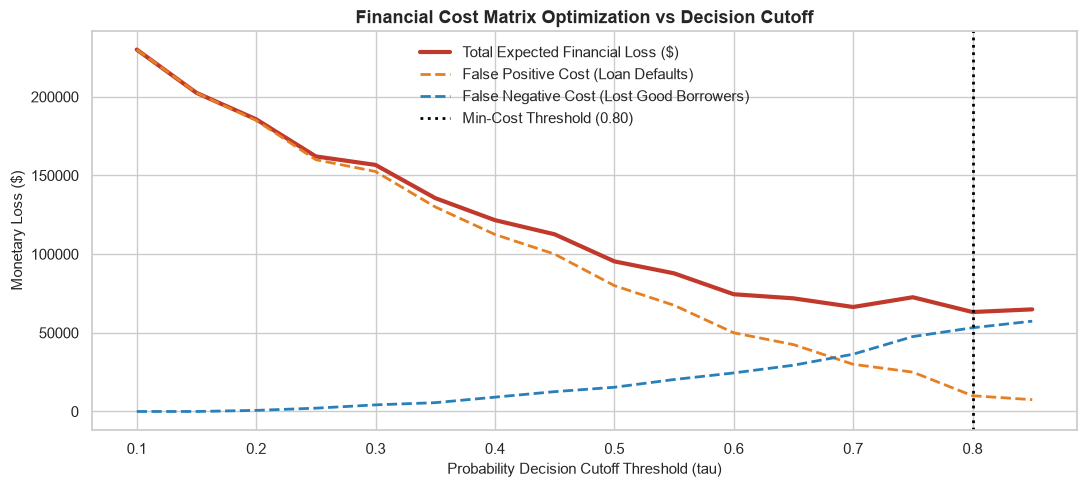

In [25]:
# Financial Cost Matrix Optimization
def evaluate_business_loss(cm, cost_fp=2500, cost_fn=700):
    # cost_fp: Cost of bad loan approval (unrecovered principal default loss = $2,500)
    # cost_fn: Cost of turning away a good applicant (lost lifetime interest profit = $700)
    tn_val, fp_val, fn_val, tp_val = cm.ravel()
    total_loss = (fp_val * cost_fp) + (fn_val * cost_fn)
    return total_loss, fp_val * cost_fp, fn_val * cost_fn

cost_simulations = []
tau_steps = np.arange(0.10, 0.90, 0.05)

for t in tau_steps:
    p_t = (y_probs >= t).astype(int)
    cm_t = confusion_matrix(y_test, p_t)
    loss, fp_l, fn_l = evaluate_business_loss(cm_t, cost_fp=2500, cost_fn=700)
    cost_simulations.append({
        'Threshold (tau)': round(t, 2),
        'Total Expected Loss ($)': loss,
        'FP Default Loss ($)': fp_l,
        'FN Lost Profit ($)': fn_l
    })

cost_df = pd.DataFrame(cost_simulations)
optimal_idx = cost_df['Total Expected Loss ($)'].idxmin()
best_tau = cost_df.loc[optimal_idx, 'Threshold (tau)']
min_loss = cost_df.loc[optimal_idx, 'Total Expected Loss ($)']

print(f"Financially Optimal Cutoff Threshold: tau = {best_tau:.2f}")
print(f"Minimum Expected Loss: ${min_loss:,.2f}")

plt.figure(figsize=(11, 5))
plt.plot(cost_df['Threshold (tau)'], cost_df['Total Expected Loss ($)'], color='#c0392b', lw=3, label='Total Expected Financial Loss ($)')
plt.plot(cost_df['Threshold (tau)'], cost_df['FP Default Loss ($)'], color='#e67e22', linestyle='--', lw=2, label='False Positive Cost (Loan Defaults)')
plt.plot(cost_df['Threshold (tau)'], cost_df['FN Lost Profit ($)'], color='#2980b9', linestyle='--', lw=2, label='False Negative Cost (Lost Good Borrowers)')
plt.axvline(best_tau, color='black', linestyle=':', lw=2, label=f'Min-Cost Threshold ({best_tau:.2f})')
plt.title("Financial Cost Matrix Optimization vs Decision Cutoff", fontsize=13, fontweight='bold')
plt.xlabel("Probability Decision Cutoff Threshold (tau)", fontsize=11)
plt.ylabel("Monetary Loss ($)", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

## 12. Summary & Key Takeaways

1. **Accuracy is a blunt, easily deceived instrument**:
   - High accuracy on imbalanced data often reflects majority class dominance, not model competence. Always check class proportions first.
2. **The Confusion Matrix is the ground truth foundation**:
   - Breaks predictions into True Positives (TP), True Negatives (TN), False Positives (FP), and False Negatives (FN). Every single classification metric is derived from these four counts.
3. **Precision and Recall represent opposite operational goals**:
   - **Precision** $= \frac{TP}{TP + FP}$: Measures trustworthiness of positive alerts. Maximize when False Alarms are costly (spam filter).
   - **Recall** $= \frac{TP}{TP + FN}$: Measures completeness of finding positive events. Maximize when Missed Cases are dangerous (disease, fraud).
4. **F1-Score provides honest balance via the Harmonic Mean**:
   - The harmonic mean penalizes large gaps between Precision and Recall far more severely than the arithmetic mean. It only looks good when *both* are strong.
5. **The Decision Threshold is an operational dial**:
   - Logistic regression outputs continuous probabilities $P(Y=1|\mathbf{x})$. The default 0.5 threshold can — and should — be tuned to match business error costs.
6. **ROC-AUC measures ranking, PR-AUC measures rare event performance**:
   - ROC-AUC evaluates overall discriminative ability across all thresholds. However, on rare-event imbalanced data ($< 10\%$), the Precision-Recall curve is vastly more informative.
7. **Business context always dictates metric selection**:
   - A model has no intrinsic "best" threshold until you define the asymmetric dollar or human costs of False Positives vs False Negatives.
